# ReliefReady Care Access Intelligence
Fast MVP grids on published **service types**, never effectiveness. Classification uses a grouped held-out split; clustering uses internal/stability metrics, not invented accuracy. Exports keep training and routing off the application request path.

In [1]:
from pathlib import Path
import sys, json, pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml/care_access").exists())
sys.path.insert(0, str(ROOT))
from ml.care_access.train import train_classifiers, train_clusters, ARTIFACTS
from IPython.display import display, Image
data = pd.read_csv(ROOT / "ml/care_access/data/labels.csv")
display(data.groupby("label").size().rename("published_examples").to_frame())
snapshot = json.loads((ROOT / "ml/care_access/data/access.json").read_text())
print({"areas": len(snapshot["areas"]), "resources": len(snapshot["resources"]), "fully_routed_areas": sum(x == 1 for x in snapshot["drivingCoverage"])})

,published_examples
label,
Ambulatory Health Care Services,350
Clinic,350
Diagnostic Services,350
Health Centre,350
Hospital,350
Mental Health,350
Miscellaneous,350
Nursing And Residential Care Facilities,350
Pharmacy,350


{'areas': 223, 'resources': 299, 'fully_routed_areas': 150}


## Supervised grids
TF-IDF → SVD32 → classifier stays inside training CV. Logistic Regression:6 combinations; Random Forest:4; Gradient Boosting:4; three folds each. Choose by training CV macro F1, then report the untouched test. Type/source_class/location/IDs are excluded from input. Same normalized names stay together; related brand wording may still overlap. Balanced national sampling does not estimate natural Calgary prevalence.

In [2]:
classification = train_classifiers()
columns = ["model", "cv_macro_f1", "heldout_accuracy", "heldout_macro_f1", "prediction_p50_ms", "prediction_p95_ms", "seconds"]
display(pd.DataFrame(classification["results"]).reindex(columns=columns))
print("Selected:", classification["selected_model"], "| seconds:", classification["elapsed_seconds"])
display(pd.read_csv(ARTIFACTS / "classification_grid.csv").sort_values("cv_macro_f1", ascending=False))

Logistic Regression: CV F1=0.649, heldout accuracy=0.659, 0.96s


Random Forest: CV F1=0.702, heldout accuracy=0.710, 3.49s


Gradient Boosting: CV F1=0.665, heldout accuracy=0.670, 44.4s


,model,cv_macro_f1,heldout_accuracy,heldout_macro_f1,prediction_p50_ms,prediction_p95_ms,seconds
0,Logistic Regression,0.648572,0.658730,0.652090,0.411167,0.508059,0.96
1,Random Forest,0.702252,0.709524,0.703638,14.076541,14.305967,3.49
2,Gradient Boosting,0.664809,0.669841,0.661922,0.802312,0.979548,44.40
3,Majority baseline,NaN,0.082540,0.016944,NaN,NaN,NaN
4,TF-IDF/SVD nearest-centroid baseline,NaN,0.609524,0.612069,NaN,NaN,NaN


Selected: Random Forest | seconds: 50.55


,family,params,cv_macro_f1
9,Random Forest,"{'model__max_depth': None, 'model__min_samples...",0.702252
7,Random Forest,"{'model__max_depth': 12, 'model__min_samples_l...",0.696448
6,Random Forest,"{'model__max_depth': 12, 'model__min_samples_l...",0.692818
8,Random Forest,"{'model__max_depth': None, 'model__min_samples...",0.689574
13,Gradient Boosting,"{'model__learning_rate': 0.08, 'model__max_dep...",0.664809
12,Gradient Boosting,"{'model__learning_rate': 0.08, 'model__max_dep...",0.655974
4,Logistic Regression,"{'model__C': 3.0, 'model__class_weight': None}",0.648572
5,Logistic Regression,"{'model__C': 3.0, 'model__class_weight': 'bala...",0.647274
2,Logistic Regression,"{'model__C': 1.0, 'model__class_weight': None}",0.641618
3,Logistic Regression,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.639283


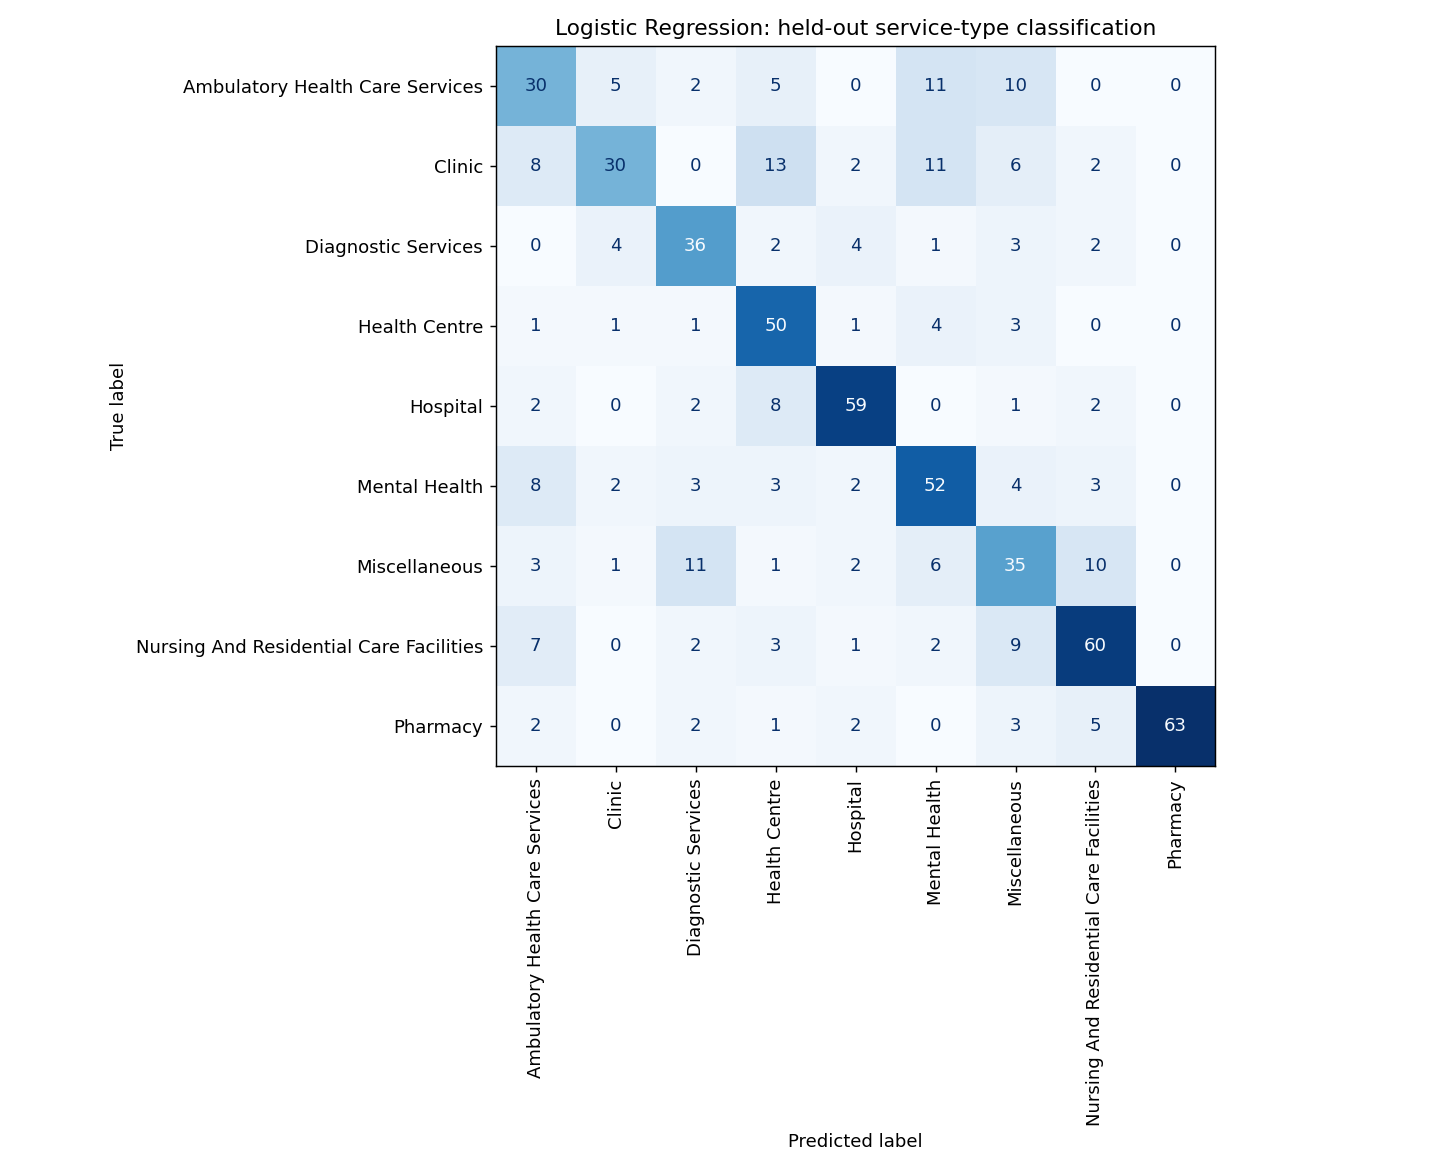

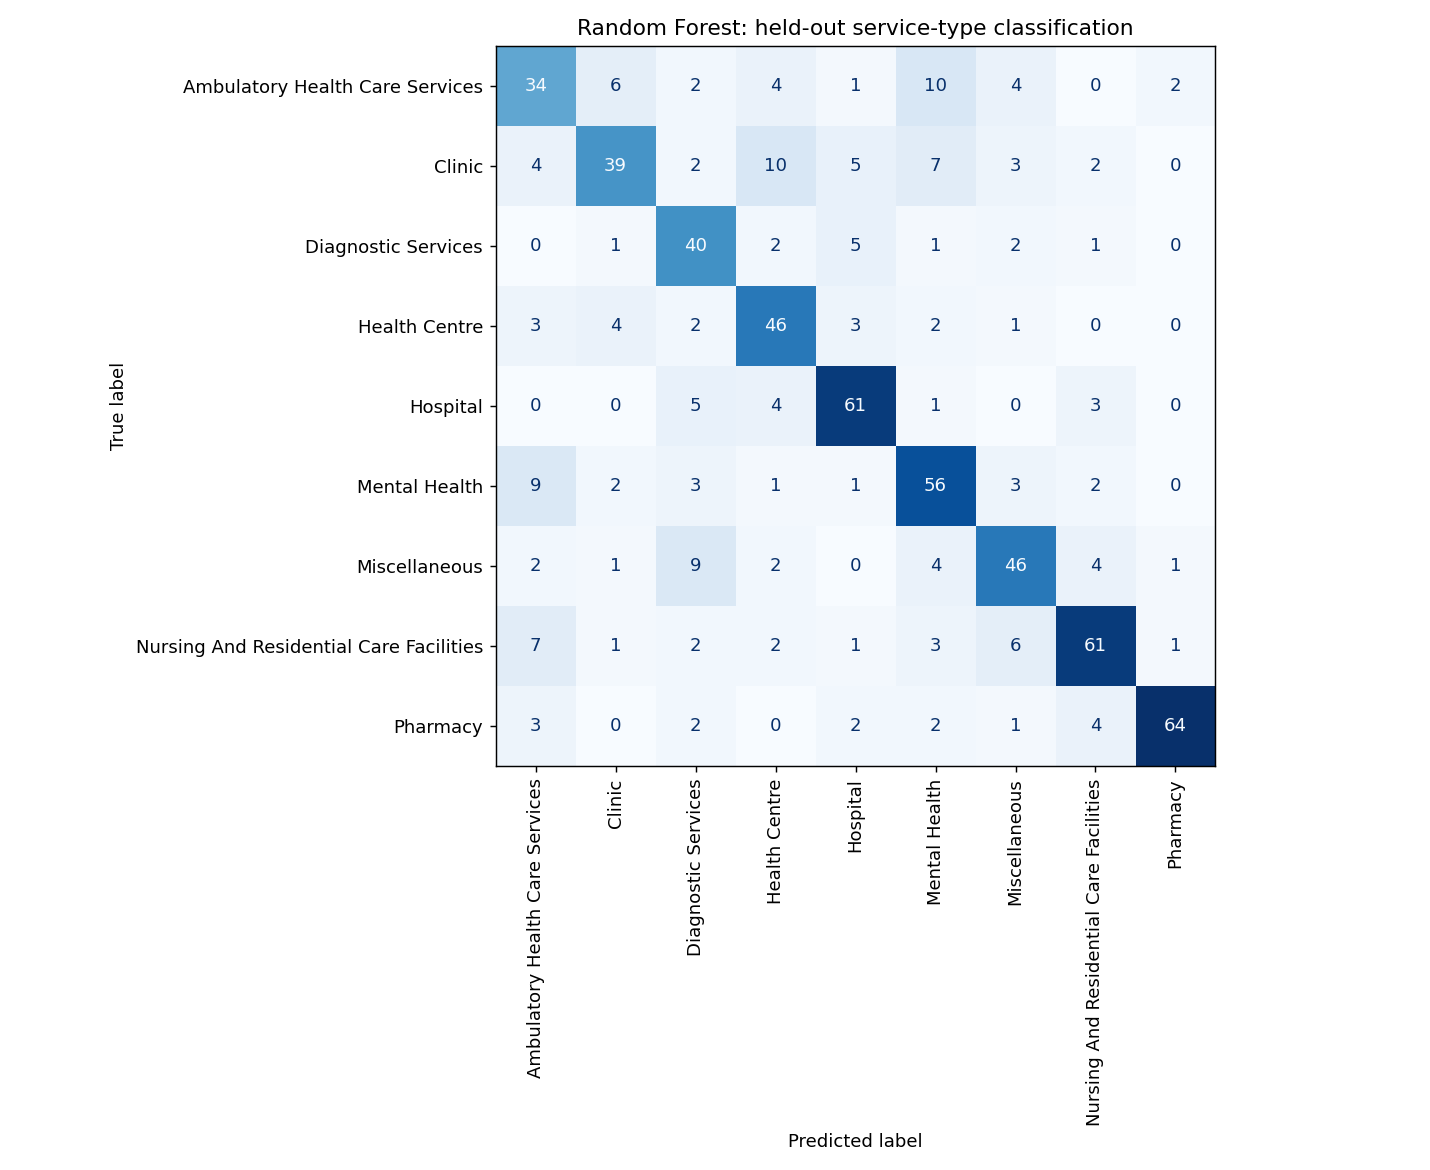

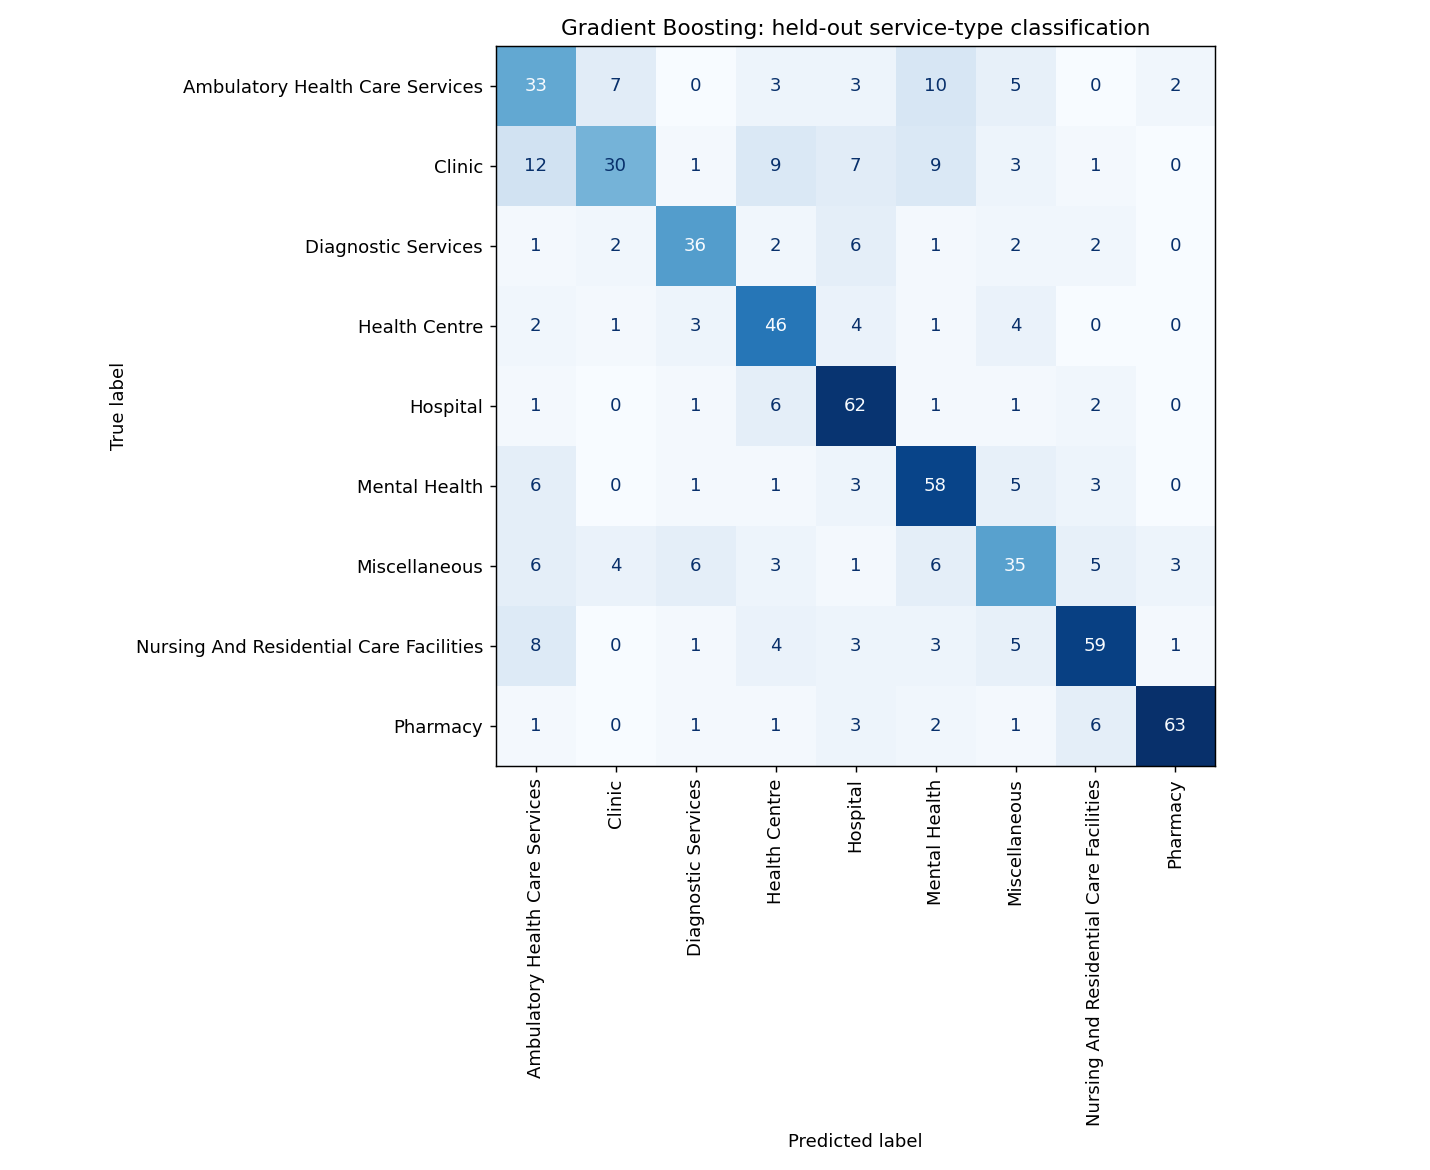

In [3]:
for family in ["logistic_regression", "random_forest", "gradient_boosting"]:
    display(Image(filename=str(ARTIFACTS / f"{family}_confusion.png")))

## Unsupervised access profiles
Compare K-means, Gaussian Mixture and DBSCAN across small grids. Standardize log resource-count features, **not latitude/longitude**. Use actual driving durations only for completely queried areas, otherwise label proximity explicitly. Reject degenerate/mostly-noise partitions. Silhouette, Davies–Bouldin, Calinski–Harabasz and perturbation ARI are diagnostics, not clinical validation or accuracy. Cluster IDs are unordered.

In [4]:
clustering = train_clusters()
display(pd.DataFrame(clustering["search"]).sort_values("silhouette", ascending=False))
print("Selected:", clustering["selected"], "| basis:", clustering["basis"])
display(pd.DataFrame(clustering["profiles"]))
print(clustering["accuracy_reason"])

{"selected_cluster": {"algorithm": "KMeans", "parameters": {"k": 2}, "silhouette": 0.6660199316749286, "davies_bouldin": 0.6209223792700983, "calinski_harabasz": 263.6710160475642, "coverage": 1.0, "clusters": 2, "perturbation_ari": 1.0}, "basis": "driving", "profile_rows": 150, "snapshot_bytes": 1006607}


,algorithm,parameters,silhouette,davies_bouldin,calinski_harabasz,coverage,clusters,perturbation_ari
0,KMeans,{'k': 2},0.666020,0.620922,263.671016,1.000000,2,1.000000
16,DBSCAN,"{'eps': 1.2, 'min_samples': 4}",0.659442,0.368847,105.808567,0.840000,2,1.000000
17,DBSCAN,"{'eps': 1.2, 'min_samples': 8}",0.659442,0.368847,105.808567,0.840000,2,1.000000
5,Gaussian Mixture,"{'k': 2, 'covariance': 'diag'}",0.654997,0.639112,251.673222,1.000000,2,0.969267
6,Gaussian Mixture,"{'k': 2, 'covariance': 'full'}",0.629775,0.686024,225.427770,1.000000,2,1.000000
13,DBSCAN,"{'eps': 0.5, 'min_samples': 4}",0.621390,0.520433,195.465253,0.726667,6,1.000000
15,DBSCAN,"{'eps': 0.8, 'min_samples': 8}",0.544368,0.707252,113.586819,0.720000,4,1.000000
1,KMeans,{'k': 3},0.527042,0.817738,212.229126,1.000000,3,1.000000
2,KMeans,{'k': 4},0.501720,0.788591,235.577802,1.000000,4,0.917862
4,KMeans,{'k': 6},0.498871,1.009464,214.417410,1.000000,6,0.833361


Selected: {'algorithm': 'KMeans', 'parameters': {'k': 2}, 'silhouette': 0.6660199316749286, 'davies_bouldin': 0.6209223792700983, 'calinski_harabasz': 263.6710160475642, 'coverage': 1.0, 'clusters': 2, 'perturbation_ari': 1.0} | basis: driving


,cluster,areas,mean_counts
0,0,122,"{'Pharmacy_20min': 63.29, 'Health Centre_30min..."
1,1,28,"{'Pharmacy_20min': 29.29, 'Health Centre_30min..."


Unsupervised labels have no ground-truth classes. Cluster IDs are unordered.


In [5]:
import matplotlib.pyplot as plt
profiles = pd.DataFrame([{"cluster": p["cluster"], **p["mean_counts"]} for p in clustering["profiles"]]).set_index("cluster")
ax = profiles.plot.bar(figsize=(12,5))
ax.set_title("Unordered clusters: mean known reachable resource counts")
ax.set_ylabel("Resource count")
plt.tight_layout(); plt.show()

/var/folders/0f/rz7qjz5x5gj57d6tqhngk9r00000gn/T/ipykernel_54168/2935707403.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## Export and instant interaction
The fitted models are serialized once. The public snapshot holds real records, source dates/hashes, cached matrices, cluster labels and metrics. Browser filtering does not call Python, routing or training. The access score is a capped resource-coverage formula, **not an ML prediction**. Unknown hours, step-free access and current availability stay unknown. Transit requires a real GTFS routing adapter; nearby stops are not travel times. No demographics infer a person's health/mobility.

In [6]:
from ml.care_access.inference import classify
print(classify({"texts": ["Community pharmacy", "Public health clinic"]}))
print("Artifacts:", [p.name for p in ARTIFACTS.iterdir() if p.is_file()])
print("Snapshot:", ROOT / "public/care-access/snapshot.json")

{'predictions': [{'category': 'Pharmacy', 'scope': 'service type only'}, {'category': 'Clinic', 'scope': 'service type only'}], 'limitations': 'No claims of effectiveness, quality, availability or eligibility'}
Artifacts: ['classification_grid.csv', 'gradient_boosting_confusion.png', 'random_forest_confusion.png', 'clustering.json', 'logistic_regression_confusion.png', 'classifier.joblib', 'clusters.joblib', 'manifest.json', 'classification.json']
Snapshot: /private/tmp/reliefready-care-access/public/care-access/snapshot.json
